# Homework #4 – Evaluation Metrics for Classification

Dataset: 2026 lead-scoring data. Target: `converted` (has the client signed up to the platform or not).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score

In [2]:
URL = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
LOCAL = 'course_lead_scoring_2026.csv'

df = pd.read_csv(LOCAL if os.path.exists(LOCAL) else URL)
df.shape

(5000, 9)

In [3]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Data preparation

* Categorical features: replace missing with `'NA'`
* Numerical features: replace missing with `0.0`

In [4]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
target = 'converted'

categorical = df.select_dtypes(exclude='number').columns.to_list()
numerical = [c for c in df.select_dtypes(include='number').columns if c != target]

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

print('Categorical:', categorical)
print('Numerical:  ', numerical)
print('Missing values left:', df.isna().sum().sum())

Categorical: ['lead_source', 'industry', 'employment_status', 'location']
Numerical:   ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
Missing values left: 0


## Split the data

60% / 20% / 20% with the exact calls from the homework (`random_state=1`).

In [6]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.pop(target).values
y_val = df_val.pop(target).values
y_test = df_test.pop(target).values

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

## Question 1: ROC AUC feature importance

Use each numerical variable as a score on the training set. If its AUC < 0.5, negate it.

In [7]:
auc_scores = {}
for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
        print(f'{col} inverted')
    auc_scores[col] = auc

auc_scores = pd.Series(auc_scores).sort_values(ascending=False)
auc_scores.to_frame('AUC')

,AUC
lead_score,0.788225
interaction_count,0.764920
number_of_courses_viewed,0.722989
annual_income,0.608198


In [8]:
print('Answer Q1:', auc_scores.index[0])

Answer Q1: lead_score


## Question 2: Training the model

One-hot encoding with `DictVectorizer` and
`LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`.

In [9]:
features = categorical + numerical

def train(df_tr, y_tr, C=1.0):
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(df_tr[features].to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y_tr)
    return dv, model

def predict(df_, dv, model):
    X = dv.transform(df_[features].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]

In [10]:
dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)

val_auc = roc_auc_score(y_val, y_pred)
print('Validation AUC:', val_auc)
print('Answer Q2:', round(val_auc, 3))

Validation AUC: 0.7318222288173319
Answer Q2: 0.732


## Question 3: Precision and Recall

Evaluate thresholds from 0.0 to 1.0 with step 0.01.

In [11]:
def compute_metrics(y_true, y_pred):
    rows = []
    for t in np.round(np.arange(0.0, 1.01, 0.01), 2):
        actual_pos = (y_true == 1)
        predict_pos = (y_pred >= t)

        tp = (predict_pos & actual_pos).sum()
        fp = (predict_pos & ~actual_pos).sum()
        fn = (~predict_pos & actual_pos).sum()

        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        rows.append((t, tp, fp, fn, precision, recall))

    return pd.DataFrame(rows, columns=['threshold', 'tp', 'fp', 'fn', 'precision', 'recall'])

df_scores = compute_metrics(y_val, y_pred)
df_scores[::10]

,threshold,tp,fp,fn,precision,recall
0,0.0,586,414,0,0.586000,1.000000
10,0.1,586,414,0,0.586000,1.000000
20,0.2,586,414,0,0.586000,1.000000
30,0.3,586,403,0,0.592518,1.000000
40,0.4,573,362,13,0.612834,0.977816
50,0.5,531,294,55,0.643636,0.906143
60,0.6,457,190,129,0.706337,0.779863
70,0.7,311,82,275,0.791349,0.530717
80,0.8,139,23,447,0.858025,0.237201
90,0.9,19,1,567,0.950000,0.032423


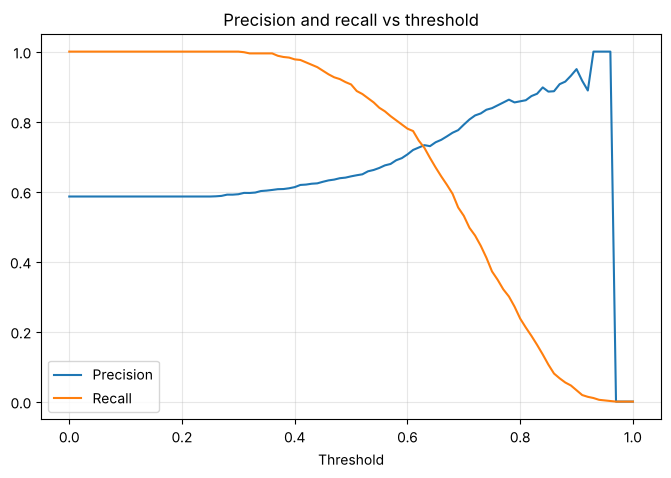

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(df_scores.threshold, df_scores.precision, label='Precision')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')
plt.xlabel('Threshold')
plt.legend()
plt.title('Precision and recall vs threshold')
plt.grid(alpha=0.3)
plt.show()

In [13]:
# ignore thresholds where both metrics are zero
valid = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)].copy()
valid['diff'] = (valid.precision - valid.recall).abs()

intersection = valid.loc[valid['diff'].idxmin()]
print(intersection[['threshold', 'precision', 'recall', 'diff']])
print('Answer Q3:', intersection.threshold)

threshold    0.630000
precision    0.732759
recall       0.725256
diff         0.007503
Name: 63, dtype: float64
Answer Q3: 0.63


## Question 4: F1 score

$$F_1 = 2 \cdot \frac{P \cdot R}{P + R}$$

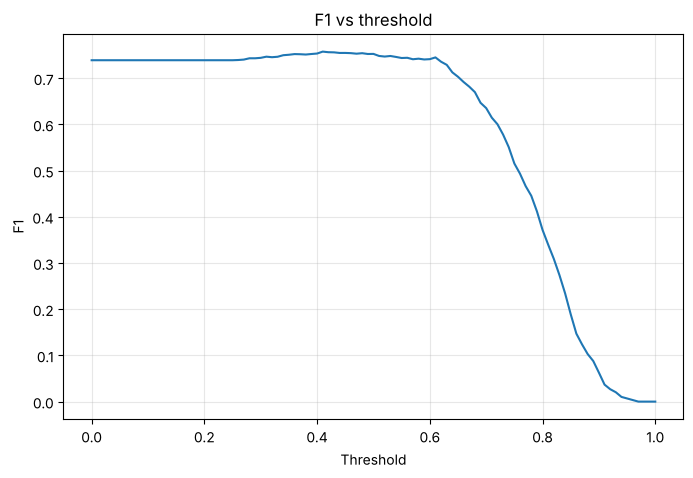

In [14]:
p, r = df_scores.precision, df_scores.recall
df_scores['f1'] = np.where((p + r) > 0, 2 * p * r / (p + r), 0.0)

plt.figure(figsize=(8, 5))
plt.plot(df_scores.threshold, df_scores.f1)
plt.xlabel('Threshold')
plt.ylabel('F1')
plt.title('F1 vs threshold')
plt.grid(alpha=0.3)
plt.show()

In [15]:
best_f1 = df_scores.loc[df_scores.f1.idxmax()]
print(best_f1[['threshold', 'precision', 'recall', 'f1']])
print('Answer Q4:', best_f1.threshold)

threshold    0.410000
precision    0.619048
recall       0.976109
f1           0.757616
Name: 41, dtype: float64
Answer Q4: 0.41


## Question 5: 5-Fold CV

`KFold(n_splits=5, shuffle=True, random_state=1)` over `df_full_train`.

In [16]:
def cross_validate(C=1.0):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_v = df_full_train.iloc[val_idx]

        dv, model = train(df_tr, df_tr[target].values, C=C)
        y_p = predict(df_v, dv, model)
        scores.append(roc_auc_score(df_v[target].values, y_p))
    return np.array(scores)

In [17]:
cv_scores = cross_validate(C=1.0)
print('Fold AUCs:', cv_scores.round(3))
print(f'Mean = {cv_scores.mean():.3f}, std = {cv_scores.std():.3f}')
print('Answer Q5:', round(cv_scores.std(), 3))

Fold AUCs: [0.731 0.73  0.736 0.741 0.721]
Mean = 0.732, std = 0.007
Answer Q5: 0.007


## Question 6: Hyperparameter Tuning

Try `C` in `[0.000001, 0.001, 1]`. Ties → lowest std → smallest `C`.

In [18]:
results = []
for C in [0.000001, 0.001, 1]:
    s = cross_validate(C=C)
    results.append({'C': C, 'mean': round(s.mean(), 3), 'std': round(s.std(), 3)})
    print(f'C={C:<8} mean={s.mean():.3f} +- {s.std():.3f}')

results = pd.DataFrame(results)
results

C=1e-06    mean=0.617 +- 0.019
C=0.001    mean=0.749 +- 0.010
C=1        mean=0.732 +- 0.007


,C,mean,std
0,0.000001,0.617,0.019
1,0.001000,0.749,0.010
2,1.000000,0.732,0.007


In [19]:
best = results.sort_values(['mean', 'std', 'C'], ascending=[False, True, True]).iloc[0]
print('Answer Q6:', best.C)

Answer Q6: 0.001


## Summary

In [20]:
pd.Series({
    'Q1 – highest AUC feature': auc_scores.index[0],
    'Q2 – validation AUC': round(val_auc, 3),
    'Q3 – P/R intersection threshold': intersection.threshold,
    'Q4 – max F1 threshold': best_f1.threshold,
    'Q5 – CV std': round(cv_scores.std(), 3),
    'Q6 – best C': best.C,
}).to_frame('Answer')

,Answer
Q1 – highest AUC feature,lead_score
Q2 – validation AUC,0.732
Q3 – P/R intersection threshold,0.63
Q4 – max F1 threshold,0.41
Q5 – CV std,0.007
Q6 – best C,0.001
